# Homogenization Model

## Example - Fe-Cr-Ni system

The homogenization model can simulate multiphase diffusion without having to resort to more complex methods such as phase field modeling. The model relies on the assumption that every volume element is in local equilibrium. Then fluxes are determined by the mobility and chemical potential gradient.

$$ J_k = -\Gamma_k^* \frac{\partial \mu_k^{eq}}{\partial z} $$

$$ \Gamma_k^\phi = M_k^\phi x_k^\phi $$

$$ \Gamma_k^* = f(\Gamma_k^\alpha, \Gamma_k^\beta, ...) $$

$\Gamma_k^*$ is an average mobility term that assumes certain geometry in the system. The following averaging functions are available in kawin:

1. Upper Wiener - assumes phases are continuous layers parallel to flux
2. Lower Wiener - assumes phases are continuous layers orthogonal to flux
3. Upper Hashin-Shtrikman - assumes a matrix of the phase with the fastest mobility with spheres of all other phases
4. Lower Hashin-Shtrikman - assumes a matrix of the phase with the slowest mobility with spheres of all other phases
5. Labyrinth - assumes phases as precipitates

Note that the Hashin-Shtrikman bounds are much narrower than the Wiener bounds.

The fluxes are calculated in a lattice fixed frame of reference. To convert to a volume fixed frame, the flux is then defined by:

$$ J_k^v = J_k - x_k \sum{J_j} $$

In this example a Fe-25.7Cr-6.5Ni / Fe-42.3Cr-27.6Ni diffusion couple will be simulated using the lower and upper Hashin-Shtrikman bounds. Both sides of the diffusion couple are $\alpha+\gamma$.

The first step is the load the thermodynamic database.

In [5]:
from kawin.thermo.thermodynamics import Thermodynamics

elements = ['FE', 'CR', 'NI']
phases = ['FCC_A1', 'BCC_A2']

therm = Thermodynamics('FeCrNi.tdb', elements+['VA'], phases)

In [6]:
from kawin.diffusion.homogenization import HomogenizationModel, hashin_shtrikman_lower, hashin_shtrikman_upper
from kawin.diffusion.mesh.fvm import Cartesian1D, StepProfile1D

mesh = Cartesian1D(['CR', 'NI'], [-5e-4, 5e-4], 200)
mesh.profile.add_build_step(StepProfile1D(0, [0.257, 0.065], [0.423, 0.276]), ['CR', 'NI'])
temperature = 1100+273.15

Defining the homogenization model is similar to defining the single phase diffusion model where the bounds of the domain, the number of volume elements, the defined elements and the defined phases are needed.

As with the single phase diffusion model, inputting the composition profile and parameters are also the same. The only difference is that two extra parameters will be defined for the homogenization model:

Smoothing factor ($\varepsilon$) - this factor allows for the composition to smooth out when the chemical potential gradient is zero but the composition gradient is non-zero (in n-phase regions where n is the number of components). This can be viewed as an ideal contribution where the composition smoothes out to maximize entropy. By default, it is set to 0.05, but here, we will set it to 0.01.

Mobility function - this defined which of the above mentioned mobility functions to use. We will start with the lower Hashin-Shtrikman bounds.

Solving the model is also similar to the single phase diffusion model.

In [7]:
from kawin.state_process import Solver

ml = HomogenizationModel(
    mesh, elements, phases,
    therm, temperature, averaging_function=hashin_shtrikman_lower, eps=0.01)
sl = ml.initialize_state()
Solver.solve(sl, ml, 100*3600)

0 0
100 83764.87939876145
200 279451.28776221426


The next model will be the exact same except the mobility function will be switched to the upper Hashin-Shtrikman bounds.

In [8]:
mu = HomogenizationModel(
    mesh, elements, phases,
    therm, temperature, averaging_function=hashin_shtrikman_upper, eps=0.01)
su = mu.initialize_state()
Solver.solve(su, mu, 100*3600)

0 0
100 6005.753036380031
200 17506.733150809403
300 30032.22755765162
400 41456.98860815222
500 52143.110436666866
600 62995.74495174017
700 73719.282735209
800 85739.71958782582
900 96255.53229868364
1000 106568.67820093824
1100 116913.1506944721
1200 127209.64776225491
1300 137713.27032483314
1400 148134.93017777335
1500 158572.44855799084
1600 168810.8999546089
1700 179039.4931209983
1800 189662.5795806347
1900 200002.62637143087
2000 210428.62708084518
2100 220480.26246235537
2200 231531.74406651474
2300 242447.4089290965
2400 255286.98079161742
2500 266054.651690922
2600 276551.01401968807
2700 286773.99330131937
2800 297399.36543371127
2900 307847.77792507276
3000 318418.59271279
3100 329484.3863049896
3200 340094.7885740127
3300 350759.0758979579


To compare the two mobility functions, the Cr composition, Ni composition and $\alpha$ phase fraction profile will be plotted. By default, the plotting functions will plot all components or phases; however, an individual component or phase can be defined to have it be the only thing that is plotted.

Here, we can see that the upper Hashin-Shtrikman bounds gives a smoother Cr and Ni profile. Additionally, the lower Hashin-Shtrikman bounds shows a pure $\gamma$ layer near the interface of around 4-6 $\mu m$.

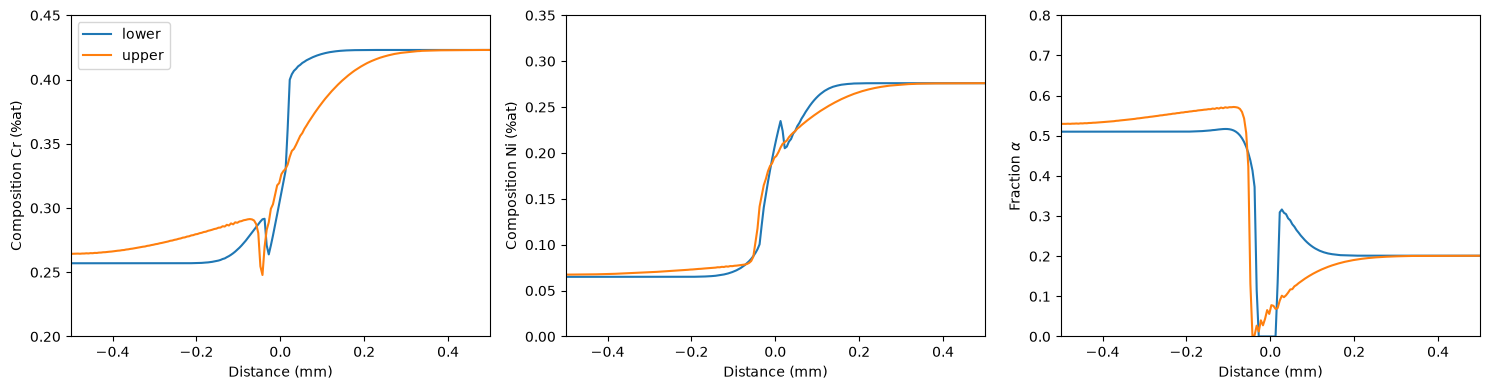

In [9]:
import matplotlib.pyplot as plt
from kawin.diffusion.plot import plot_1d, plot_1d_phases

fig, ax = plt.subplots(1,3, figsize=(15,4))

plot_1d(sl, ml, 'CR', z_scale=1e-3, ax=ax[0], label='lower')
plot_1d(su, mu, 'CR', z_scale=1e-3, ax=ax[0], label='upper')
ax[0].set_xlabel('Distance (mm)')
ax[0].set_ylabel('Composition Cr (%at)')
ax[0].set_ylim([0.2, 0.45])
ax[0].legend()

plot_1d(sl, ml, 'NI', z_scale=1e-3, ax=ax[1], label='lower')
plot_1d(su, mu, 'NI', z_scale=1e-3, ax=ax[1], label='upper')
ax[1].set_xlabel('Distance (mm)')
ax[1].set_ylabel('Composition Ni (%at)')
ax[1].set_ylim([0, 0.35])

plot_1d_phases(sl, ml, 'BCC_A2', z_scale=1e-3, ax=ax[2], label='lower')
plot_1d_phases(su, mu, 'BCC_A2', z_scale=1e-3, ax=ax[2], label='upper')
ax[2].set_xlabel('Distance (mm)')
ax[2].set_ylabel(r'Fraction $\alpha$')
ax[2].set_ylim([0, 0.8])
plt.tight_layout()
plt.show()

We can plot the composition profile on a phase diagram to further show the diffusion path and compare both mobility functions. Using the triangular plotting feature in pycalphad, the Fe-Cr-Ni ternary phase diagram can be plotted and the diffusion paths of the two homogenization models can be superimposed on top.

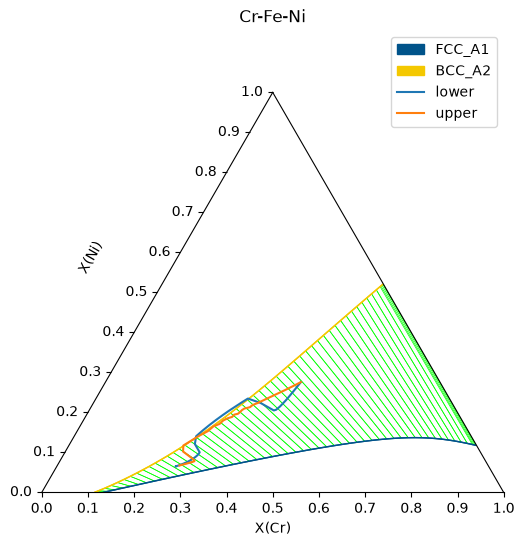

In [11]:
from pycalphad import ternplot, variables as v
from pycalphad.plot import triangular
from pycalphad.plot.utils import phase_legend

from kawin.thermo.mobility import expand_u_frac, u_to_x_frac, interstitials

get_comp = lambda state, model: u_to_x_frac(expand_u_frac(state.u_frac, model.all_elements, model.ref_element, interstitials), model.all_elements, interstitials)

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='triangular')

conds = {v.T: 1100+273.15, v.P:101325, v.X('CR'): (0,1,0.015), v.X('NI'): (0,1,0.015)}
ternplot(therm.dbf, ['FE', 'CR', 'NI', 'VA'], phases, conds, x=v.X('CR'), y=v.X('NI'), ax = ax)

# Compositions will contain all elements (dependent, independent)
compl = get_comp(sl, ml)
ln1, = ax.plot(compl[:,1], compl[:,2], label='lower')

compu = get_comp(su, mu)
ln2, = ax.plot(compu[:,1], compu[:,2], label='upper')

#The pycalphad ternplot function will automatically add a legend for the phases,
#but the legend has to be added again to add labels for the diffusion paths
handles, _ = phase_legend(phases)
ax.legend(handles = handles + [ln1, ln2])

plt.show()

### Periodic boundaries

0 0
100 83764.87939888255
200 279451.2877588866


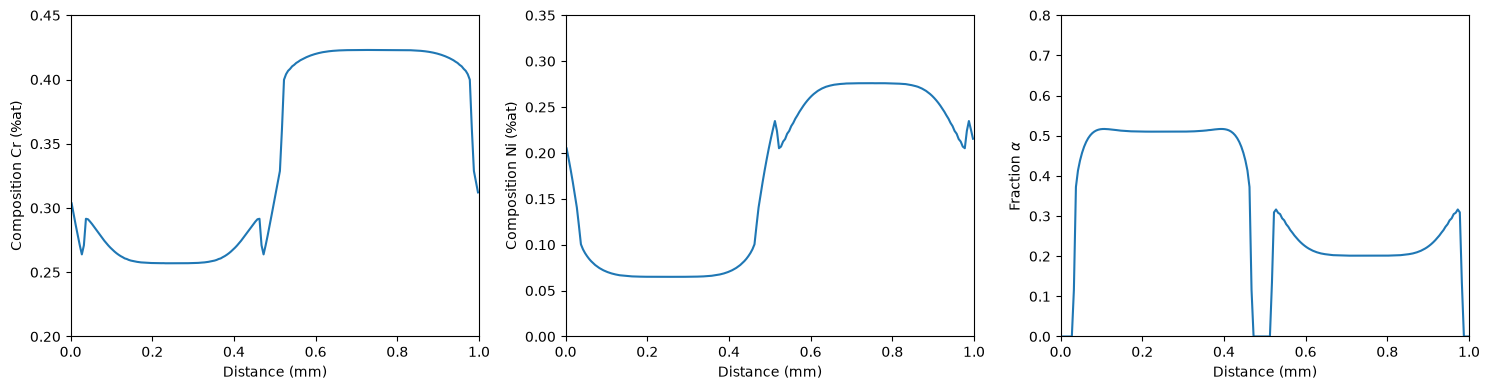

In [12]:

mesh = Cartesian1D(['CR', 'NI'], [0, 1e-3], 200)
mesh.profile.add_build_step(StepProfile1D(0.5e-3, [0.257, 0.065], [0.423, 0.276]), ['CR', 'NI'])
mesh.periodic = True

m = HomogenizationModel(
    mesh, elements, phases,
    therm, temperature, averaging_function=hashin_shtrikman_lower, eps=0.01)
state = m.initialize_state()
Solver.solve(state, m, 100*3600)

fig, ax = plt.subplots(1,3, figsize=(15,4))

plot_1d(state, m, 'CR', z_scale=1e-3, ax=ax[0])
ax[0].set_xlabel('Distance (mm)')
ax[0].set_ylabel('Composition Cr (%at)')
ax[0].set_ylim([0.2, 0.45])

plot_1d(state, m, 'NI', z_scale=1e-3, ax=ax[1])
ax[1].set_xlabel('Distance (mm)')
ax[1].set_ylabel('Composition Ni (%at)')
ax[1].set_ylim([0, 0.35])

plot_1d_phases(state, m, 'BCC_A2', z_scale=1e-3, ax=ax[2])
ax[2].set_xlabel('Distance (mm)')
ax[2].set_ylabel(r'Fraction $\alpha$')
ax[2].set_ylim([0, 0.8])
plt.tight_layout()
plt.show()

## References

1. H. Larsson and L. Hoglund, "Multiphase diffusion simulations in 1D using the DICTRA homogenization model" *Calphad* 33 (2009) p. 495
2. H. Larsson and A. Engstrom, "A homogenization approach to diffusion simulations applied to $\alpha+\gamma$ Fe-Cr-Ni diffusion couples" *Acta Materialia* 54 (2006) p. 2431